In [1]:
# the following Jupyter assumes that the installation has been perfomed in a virtual environment, installing the setup.py

from mmfex.actions import *

import matplotlib.pyplot as plt
import os

import csv

## Testing the code on a BChl dimer  
This Jupyter Notebook show the use of the `'action'` module for the creation of theb Frenkel-Davydov Hamiltonian of a dimer.
As an example, a dimer of BChls from LH2 has been considered.

* The Hamiltonian can be built from the data by hand by considering the total coupling terms among the monomers. 


In [2]:
hand_made_frenkel = np.array([
    [0.00000000E+00, -2.82165850E-03,  3.70318797E-02,  2.07085104E-02, -7.67683040E-03, -1.06048645E-02,  3.76468387E-02, -3.27280514E-03, -2.97221174E-03],
    [-2.82165850E-03,  1.62304685E+00,  1.07945853E-02, -1.89780983E-02, -1.49103107E-02,  4.91232785E-02,  9.77321356E-03,  1.92839072E-03, -1.13962492E-03],
    [3.70318797E-02,  1.07945853E-02,  2.38517076E+00,  8.82681070E-04,  5.88850704E-03, -2.03175513E-03,  1.02011704E-02, -1.18441442E-03, -6.93809197E-03],
    [2.07085104E-02, -1.89780983E-02,  8.82681070E-04,  2.57597074E+00, -7.57140154E-04, -9.90653988E-04,  1.09308979E-02, -8.74213570E-05, -7.08876116E-03],
    [-7.67683040E-03, -1.49103107E-02,  5.88850704E-03, -7.57140154E-04,  2.98468396E+00, -4.64103332E-03,  1.39373933E-03, -6.32363787E-04, -3.29956374E-04],
    [-1.06048645E-02,  4.91232785E-02, -2.03175513E-03, -9.90653988E-04, -4.64103332E-03,  1.59408777E+00,  8.47814247E-03,  2.34297008E-03,  2.34802866E-02],
    [3.76468387E-02,  9.77321356E-03,  1.02011704E-02,  1.09308979E-02,  1.39373933E-03,  8.47814247E-03,  2.40781521E+00, -7.12933388E-03, -2.29599774E-03],
    [-3.27280514E-03,  1.92839072E-03, -1.18441442E-03, -8.74213570E-05, -6.32363787E-04,  2.34297008E-03, -7.12933388E-03,  2.54370933E+00,  3.62408456E-03],
    [-2.97221174E-03, -1.13962492E-03, -6.93809197E-03, -7.08876116E-03, -3.29956374E-04,  2.34802866E-02, -2.29599774E-03,  3.62408456E-03,  2.91861996E+00]
    ])

**Then we need:**
* to set the first monomer and the last, to build the trimer in this case;
* to say the total number of states used in the CASSCF calculation;
* to set the number of states considered in the Frenkel Hamiltonian per monomer;

In [3]:
first_monomer = 301
last_monomer = 302
total_roots = 5 # total number of states used in the CASSCF calculation;
dim = 5 # number of states considered in the Frenkel Hamiltonian per monomer;

#### Collect the data  
Use the `collect` function inside the `actions` module to collect:  
* the coupling terms, 
* the excitation energies of the monomers and 
* the transition dipole moments

In [4]:
C, E, TDM = collect(first_monomer=first_monomer, 
                    last_monomer=last_monomer, 
                    computed_roots=total_roots,
                    custom_names= ['301_a', '302_a'],
                    #source = os.getcwd(),
                    wanted_roots=dim)

#### Create the corresponding Frenkel Hamiltonian  
Use the `build` function inside the `actions` module to build the Frenkel-Davydov Hamiltonian corresponding to the parameters we set.  
The unit of measurement is 'Hartree' by default, but can be set to 'eV'.

In [5]:
Frenkel = build(E=E,
                C=C,
                units='eV')

#### Create the corresponding Frenkel Hamiltonian  
Use the `build` function inside the `actions` module to build the Frenkel-Davydov Hamiltonian corresponding to the parameters we set.  
The unit of measurement is 'Hartree' by default, but can be set to 'eV'.

#### Check the Frenkel Hamiltonian  

Check that the difference between the result and the hand-made Hamiltonian corresponds (up to small numerical/truncation differences)

In [6]:
diff = hand_made_frenkel - Frenkel
print(np.all(diff <= 10e9))

True


#### Compute the physical properties of the trimer  

To do that, use the `compute` function.

In [7]:
eigenvalues, eigenvectors, oscillators, TDM_EXC = compute(Frenkel=Frenkel,
                                                TDM=TDM,
                                                units='eV',
                                                printed_output=True)

In [8]:
oscillators

array([0.58877342, 0.03963505, 0.0278315 , 0.14775114, 0.00291735,
       0.02761978, 0.00513478, 0.00172486])

if `printed_output=True` a `.out` file is generated. To see an example of the file open `trimer_demo.out`

These data can be analysed as we wish, but also used to generate a spectrum of the system using the function `get_spectrum` which give the x and y-axis of the spectrum.


In [10]:
x_axis, y_axis = get_spectrum(E=eigenvalues,
                              f = oscillators,
                              sigma=0.05, # standard deviation of the Gaussian function
                              csv = False) 

if `csv = Ture` a `.csv` file is generated containing the x and y-axis of the spectrum.

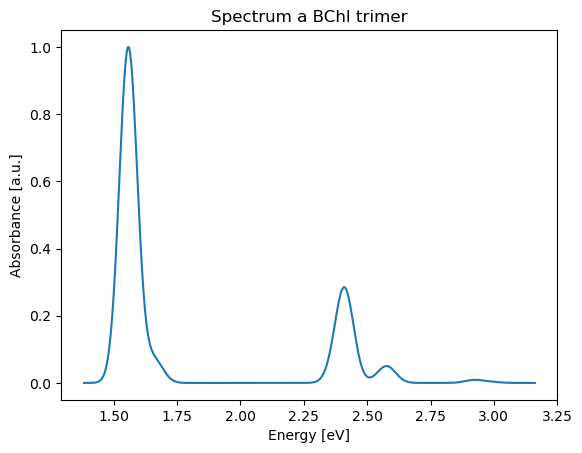

In [11]:
plt.plot(x_axis,y_axis)
plt.xlabel("Energy [eV]")
plt.ylabel("Absorbance [a.u.]")
plt.title("Spectrum a BChl trimer")
plt.show()

# Generate CSV for the absorption spectrum

In [13]:
with open("TEST.csv", "w") as f:
    writer = csv.writer(f)
    field = ["eV", "Absorbance"]

    writer.writerow(field)
    for i in range(0,len(x_axis)):
        row = [x_axis[i], y_axis[i]]
        writer.writerow(row)


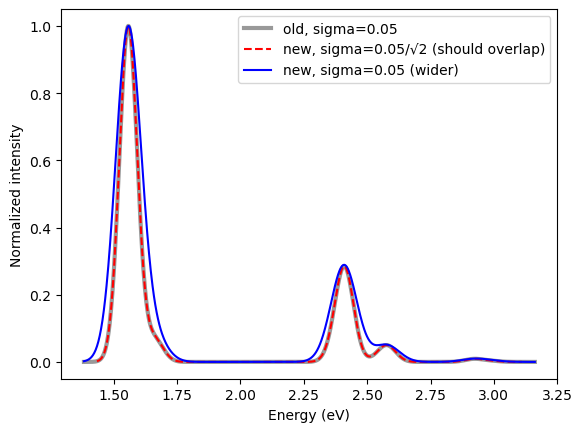

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def get_spectrum_new(E, f, sigma=0.05, n_points=1000):
    """Gaussian broadening; sigma is the true standard deviation (same units as E)."""
    E = np.asarray(E)
    f = np.asarray(f)
    if E[0] == 0:                      # drop the ground state, as the old version does
        E = E[1:]
    x = np.linspace(E.min() - 3.5*sigma, E.max() + 3.5*sigma, n_points)
    spec = np.zeros_like(x)
    for Ei, fi in zip(E, f):
        spec += fi / (sigma*np.sqrt(2*np.pi)) * np.exp(-(x - Ei)**2 / (2*sigma**2))
    return x, spec / np.max(spec)

# old function, as is
x_old, y_old = get_spectrum(E=eigenvalues, f=oscillators, sigma=0.05, csv=False)

# new function, same broadening as before: sigma_new = sigma_old / sqrt(2)
x_eq, y_eq = get_spectrum_new(eigenvalues, oscillators, sigma=0.05/np.sqrt(2))

# new function, 0.05 taken literally as the standard deviation
x_lit, y_lit = get_spectrum_new(eigenvalues, oscillators, sigma=0.05)

plt.plot(x_old, y_old, 'k', lw=3, alpha=0.4, label='old, sigma=0.05')
plt.plot(x_eq,  y_eq,  'r--', label='new, sigma=0.05/√2 (should overlap)')
plt.plot(x_lit, y_lit, 'b',   label='new, sigma=0.05 (wider)')
plt.xlabel('Energy (eV)'); plt.ylabel('Normalized intensity')
plt.legend(); plt.show()